# Nominal ringlet

epi_int_3d's nominal ringlet (`inputs.py`): 100 streamlines × 40 particles, width 0.0125 with tapered
edges, mass 3×10⁻⁸, e = 10⁻⁴ with periapses twisted by π from inner to outer edge, ν = 7×10⁻¹¹,
10⁴ orbits. Is it well behaved? Streamlines should stay smooth and never cross, self-gravity should
hold the twist against J2, and angular momentum should be conserved.

In [1]:
#put this repo's source/ folder on the import path
import os, sys
repo = os.path.abspath('.')
while not os.path.exists(os.path.join(repo, 'pyproject.toml')):
    repo = os.path.dirname(repo)
sys.path.insert(0, os.path.join(repo, 'source'))
assert os.path.isdir('output'), \
    'no output/ here: run this test first (uv run python tools/run_simulations.py ' + os.path.relpath('.', repo) + ')'

In [2]:
#restore output
from helper_fns import *
exec(open('inputs.py').read())
r, t, vr, vt, times, monitor = restore_output(output_folder)
orbits = times/(2*np.pi)
print('r.shape = ', r.shape)
print('initial_orbits = ', initial_orbits)
print('execution time (min) = ', (monitor['current_time'] - monitor['start_time'])/60.0)
print('monitor = ', monitor)

edge taper fraction = 0.2
r.shape =  (201, 100, 40)
initial_orbits =  {'shape': 'eccentric', 'e': 0.0001, 'e_prime': 0.0, 'w_prime': 0.02529}
execution time (min) =  24.366666666666667
monitor =  {'start_time': 1792355413, 'current_time': 1792356875, 'current_timestep': 125800, 'streamline_crossing_timestep': None, 'nan_timestep': None, 'self_interacting': True, 'modified_params': None}


In [3]:
#prep plots
%matplotlib inline
import seaborn as sns
import matplotlib.pyplot as plt
sns.set(font_scale=1.5, font='DejaVu Sans')
import numpy as np

In [4]:
#each streamline's shape from the m = 0, 1 Fourier terms of its r(theta): mean radius a, eccentricity e,
#and periapse w (relative to the middle streamline), fit to r = a[1 - e cos(theta - w)]. These are geometric elements, which unlike
#the particles' osculating elements are smooth across the streamline
def shape(r, t):
    a, c1, s1 = np.array([np.linalg.lstsq(np.array([np.ones_like(tk), np.cos(tk), np.sin(tk)]).T, rk, rcond=None)[0]
        for tk, rk in zip(t, r)]).T                       #least squares: particles are not evenly spaced in theta
    e = np.hypot(c1, s1)/a
    w = np.unwrap(np.arctan2(-s1, -c1))
    return a, e, w - w[len(w)//2]

#raggedness: rms residual of each streamline's r(theta) about a Fourier fit through m = 3
def raggedness(r, t, mmax=3):
    cols = [np.ones_like(t)] + [f(m*t) for m in range(1, mmax + 1) for f in (np.cos, np.sin)]
    res = []
    for k in range(r.shape[0]):
        X = np.array([c[k] for c in cols]).T
        coef = np.linalg.lstsq(X, r[k], rcond=None)[0]
        res += [np.sqrt(((r[k] - X@coef)**2).mean())]
    return np.array(res)

N = np.isfinite(r).all(axis=(1, 2)).sum()                 #outputs before any NaN
A, E, W = np.array([shape(r[k], t[k]) for k in range(N)]).transpose(1, 0, 2)
spacing = np.median(np.diff(A[0]))                        #initial spacing of the middle streamlines
#q = a|d(e exp(iw))/da| of adjacent streamlines; they touch when q -> 1
EV = E*np.exp(1j*W)
q = (0.5*(A[:, 1:] + A[:, :-1])*np.abs(np.diff(EV, axis=1))/np.diff(A, axis=1)).max(axis=1)
#smallest gap between adjacent streamlines, wrapped in longitude, over the initial spacing
gap = []
for k in range(N):
    rw = wrap_ring(r[k]); tw = wrap_ring(t[k], longitude=True)
    gap += [(rw - interpolate_fn(tw, rw, -1))[1:, 1:-1].min()/spacing]
gap = np.array(gap)
ragged = np.array([raggedness(r[k], t[k]).max() for k in range(N)])/spacing
width = (A[:, -1] - A[:, 0])/(A[0, -1] - A[0, 0])
print('outputs without NaN = ', N, ' of ', len(times))
print('max q = ', q.max())
print('min gap/spacing = ', gap.min())
print('max raggedness/spacing = ', ragged.max())
print('final width/initial width = ', width[-1])

outputs without NaN =  201  of  201
max q =  0.3870396646512415
min gap/spacing =  0.9720485783650324
max raggedness/spacing =  0.00011599881021052182
final width/initial width =  2.655401421493732


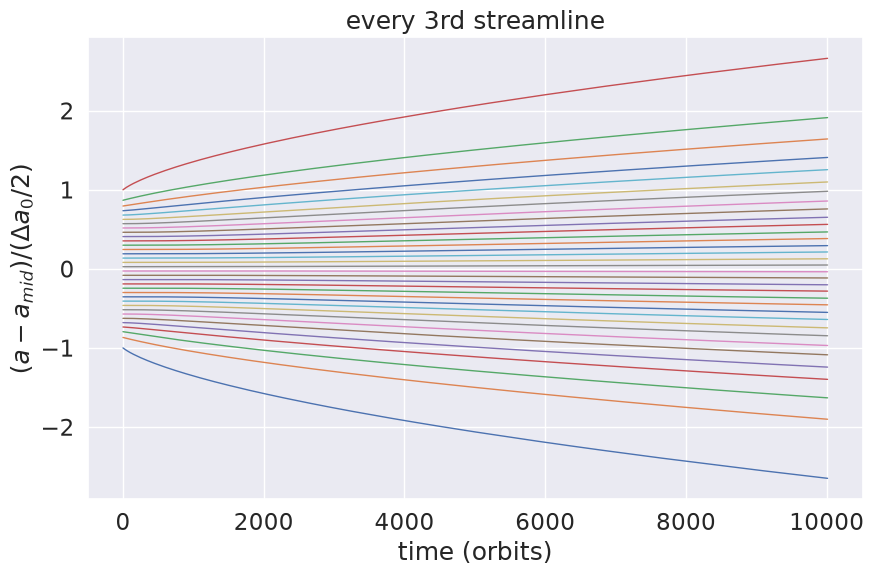

In [5]:
#plot streamlines' a-evolution, as in tests/spreading
f, ax = plt.subplots(figsize=(10, 6))
a_mid = A[0].mean()
da_0 = (A[0, -1] - A[0, 0])/2
for j in range(0, number_of_streamlines, 3):
    p = ax.plot(orbits[:N], (A[:, j] - a_mid)/da_0, linestyle='-', linewidth=1)
p = ax.set_xlabel('time (orbits)')
p = ax.set_ylabel(r'$(a - a_{mid})/(\Delta a_0/2)$')
p = ax.set_title('every 3rd streamline')

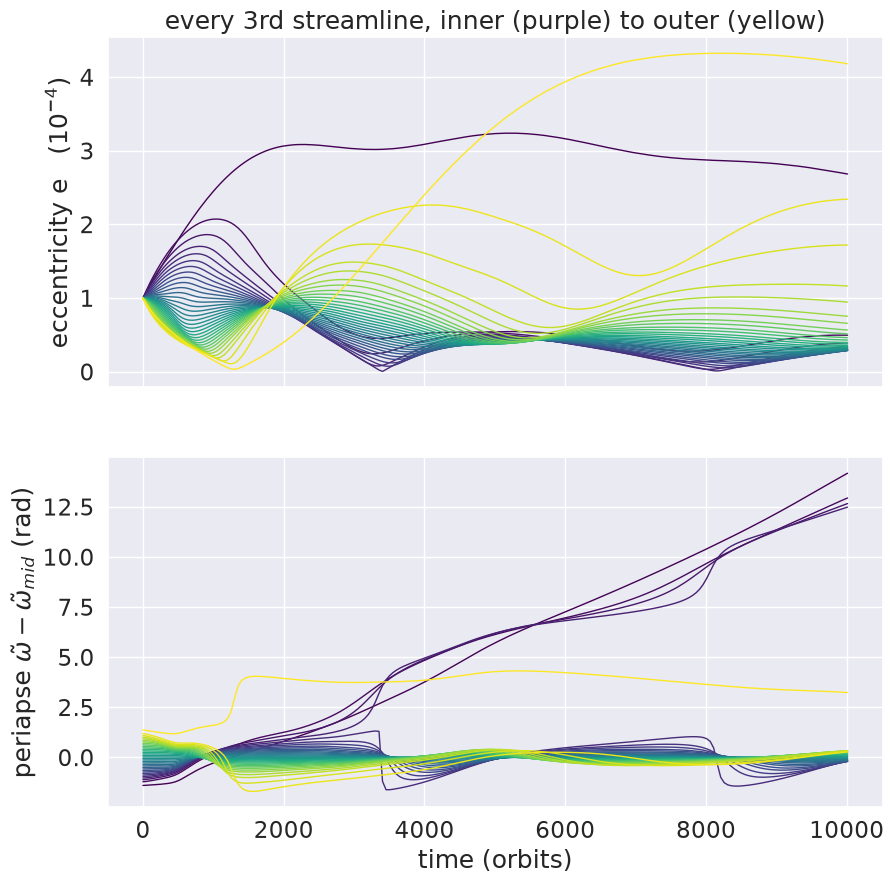

In [6]:
#plot streamlines' e(t) and w(t)
f, axs = plt.subplots(2, 1, figsize=(10, 10), sharex=True)
colors = plt.cm.viridis(np.linspace(0, 1, number_of_streamlines))
for j in range(0, number_of_streamlines, 3):
    p = axs[0].plot(orbits[:N], E[:, j]/1.0e-4, color=colors[j], linewidth=1)
    p = axs[1].plot(orbits[:N], np.unwrap(W[:, j]), color=colors[j], linewidth=1)   #continuous in time
p = axs[0].set_ylabel(r'eccentricity e   ($10^{-4}$)')
p = axs[1].set_ylabel(r'periapse $\tilde{\omega} - \tilde{\omega}_{mid}$ (rad)')
p = axs[1].set_xlabel('time (orbits)')
p = axs[0].set_title('every 3rd streamline, inner (purple) to outer (yellow)')

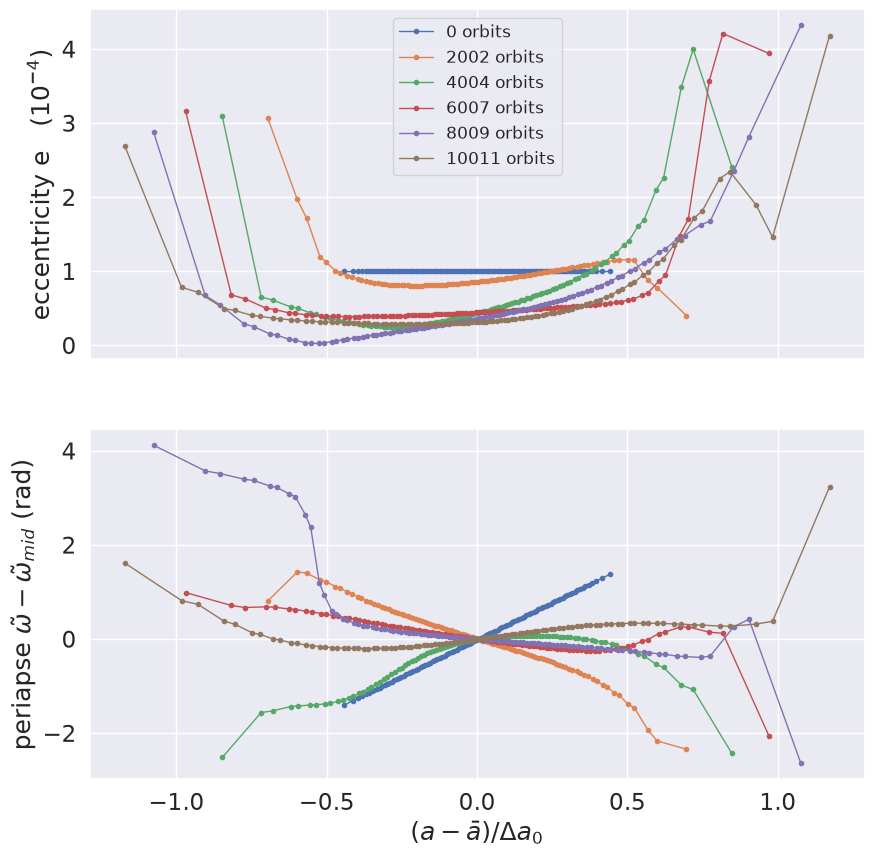

In [7]:
#plot e(a) and w(a) at selected times
f, axs = plt.subplots(2, 1, figsize=(10, 10), sharex=True)
for k in np.linspace(0, N - 1, 6).astype(int):
    x = (A[k] - A[k].mean())/radial_width
    p = axs[0].plot(x, E[k]/1.0e-4, marker='o', markersize=3, linewidth=1, label=f'{orbits[k]:.0f} orbits')
    p = axs[1].plot(x, W[k], marker='o', markersize=3, linewidth=1)
p = axs[0].set_ylabel(r'eccentricity e   ($10^{-4}$)')
p = axs[1].set_ylabel(r'periapse $\tilde{\omega} - \tilde{\omega}_{mid}$ (rad)')
p = axs[1].set_xlabel(r'$(a - \bar{a})/\Delta a_0$')
p = axs[0].legend(fontsize=12)

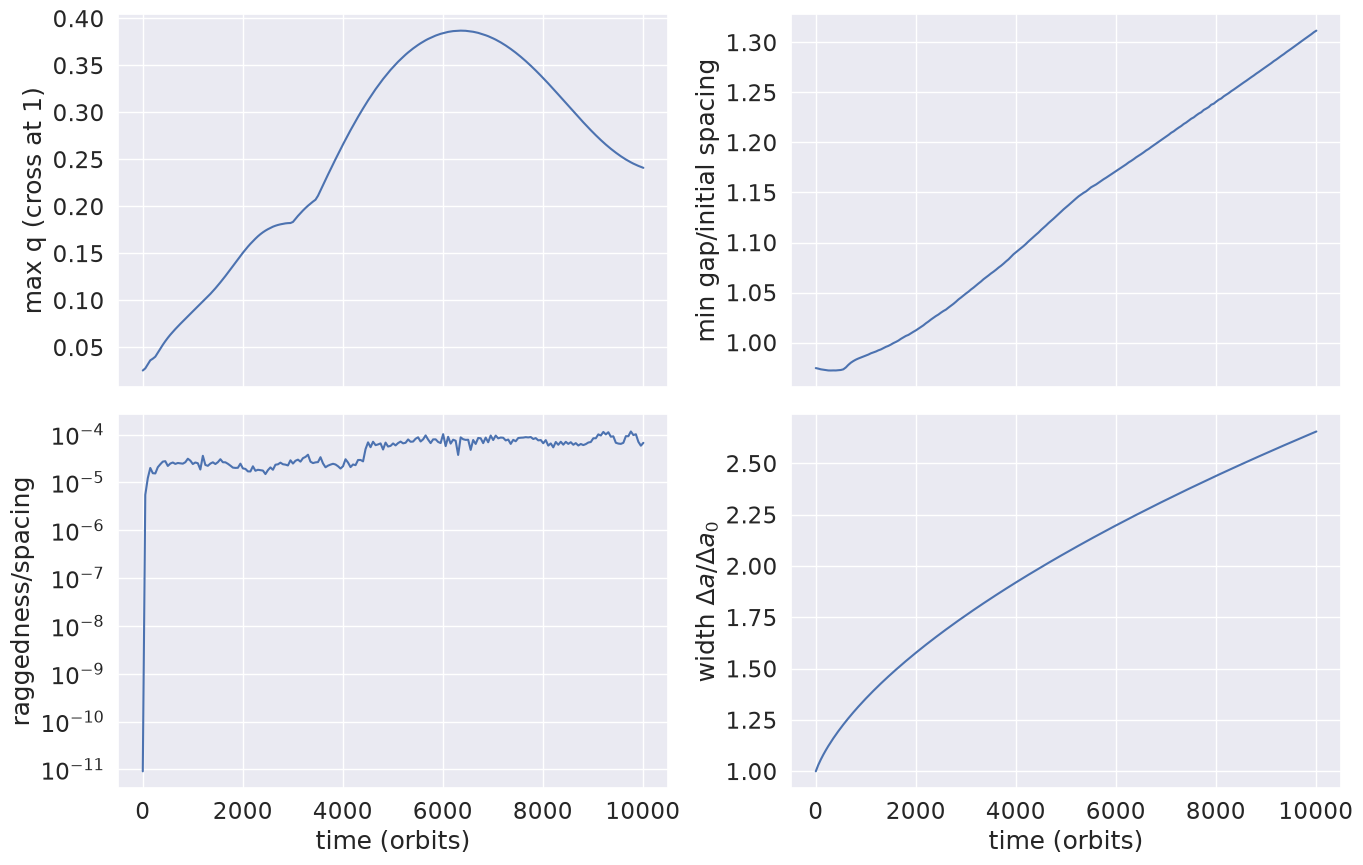

In [8]:
#plot nonlinearity q, smallest gap, raggedness, and width versus time
f, axs = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
p = axs[0, 0].plot(orbits[:N], q)
p = axs[0, 0].set_ylabel('max q (cross at 1)')
p = axs[0, 1].plot(orbits[:N], gap)
p = axs[0, 1].set_ylabel('min gap/initial spacing')
p = axs[1, 0].semilogy(orbits[:N], ragged)
p = axs[1, 0].set_ylabel('raggedness/spacing')
p = axs[1, 1].plot(orbits[:N], width)
p = axs[1, 1].set_ylabel(r'width $\Delta a/\Delta a_0$')
for ax in axs[1]:
    p = ax.set_xlabel('time (orbits)')
f.tight_layout()

max |delta L/L_0| =  1.2953781333322417e-05


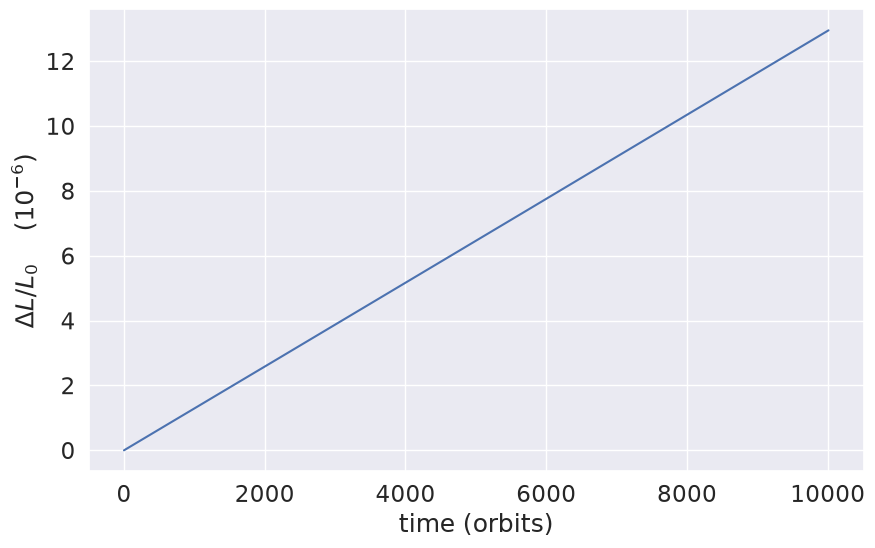

In [9]:
#total angular momentum in the barycentric frame, as in tests/spreading
particle_mass = total_ring_mass/(number_of_streamlines*particles_per_streamline)
L = []
for k in range(N):
    r_bc, t_bc, vr_bc, vt_bc, r_0, t_0, vr_0, vt_0 = planeto2bary(total_ring_mass, r[k], t[k], vr[k], vt[k])
    L += [1.0*r_0*vt_0 + np.sum(particle_mass*r_bc*vt_bc)]
L = np.array(L)
delta_L = (L - L[0])/L[0]
print('max |delta L/L_0| = ', np.abs(delta_L).max())
f, ax = plt.subplots(figsize=(10, 6))
p = ax.plot(orbits[:N], delta_L/1.0e-6)
p = ax.set_ylabel(r'$\Delta L/L_0$    $(10^{-6})$')
p = ax.set_xlabel('time (orbits)')

In [10]:
#is the nominal ringlet well behaved?
checks = {
    'no NaN': N == len(times) and monitor['nan_timestep'] is None,
    'no crossing': monitor['streamline_crossing_timestep'] is None and gap.min() > 0,
    'q < 0.5 (twist held)': q.max() < 0.5,
    'smooth: raggedness < 1e-3 spacings': ragged.max() < 1.0e-3,
}
for name, ok in checks.items():
    print('PASS' if ok else 'FAIL', ' ', name)
assert all(checks.values())

PASS   no NaN
PASS   no crossing
PASS   q < 0.5 (twist held)
PASS   smooth: raggedness < 1e-3 spacings
